# Figure S2

Detectability of gene-pair associations by Fisher's exact test depends on lineage number, multiple-testing burden, and association direction (Additional file 2).

- **A**: power to detect co-occurrence at OR = 10 against the number of independent lineages, N (`draw_power_panel`).
- **B**: power to detect mutual exclusivity at OR = 1/10, drawn the same way (`draw_power_panel`).
- **C**: single-pair power over lineage number and odds ratio (`draw_panelC`).

Inputs: `cache/Figure_S2_power_sweep.npz` (written by `code/Figure_S2_power_sweep.py` in environment B) and `data/analysis/ecoli/all_experiments/per_experiment_summary_gene.csv`.

Outputs in `figures/Figure_S2/`, each as SVG and PNG: `Figure_S2` (A, B and C on one canvas, with the key of A and B, the color bar of C and the panel letters), `Figure_S2_AB` (A and B with their key), `Figure_S2_C`, `Figure_S2_key_AB` (the shared legend of A and B) and `Figure_S2_key_C` (the color bar of C).

Environment A. The final layout is set in Adobe Illustrator.

In [1]:
# %% Imports and shared style (matches Figure_1.ipynb)
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

mpl.rcParams["svg.fonttype"] = "none"
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["figure.facecolor"] = "white"
mpl.rcParams["axes.facecolor"] = "white"
mpl.rcParams["font.family"] = "sans-serif"
mpl.rcParams["font.sans-serif"] = ["Arial", "Helvetica", "DejaVu Sans"]
mpl.rcParams["axes.spines.top"] = False
mpl.rcParams["axes.spines.right"] = False

# Palette. The two design-curve lines are one hue, two lightnesses.
INK = "#000000"; MUTE = "#7a828b"
BLUE_D = "#08519C"; BLUE_L = "#6BAED6"        # 42C_Tenaillon correction family / single pre-specified pair
THRESH = "#666666"                            # 80% reference line

FS = {"axis": 13, "tick": 12, "legend": 11, "annot": 11,
      "panel_label": 16}                 # panel_label: the letters A to C (bold)
mpl.rcParams["text.color"] = INK
mpl.rcParams["axes.labelcolor"] = INK
mpl.rcParams["xtick.color"] = INK
mpl.rcParams["ytick.color"] = INK

# Folders. The notebook runs from code/, so the folder above it holds data/, cache/ and figures/.
ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"            # pipeline outputs (the results/ folder of ale-cooccurrence-mutual-exclusivity-nf)
FIG_DIR = ROOT / "figures/Figure_S2"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"data folder not found: {DATA_DIR}")
if not (ROOT / "code/Figure_S2.ipynb").is_file():
    raise FileNotFoundError(f"run this notebook from the code/ folder (working folder: {Path.cwd()})")
FIG_DIR.mkdir(parents=True, exist_ok=True)
SAVE, DPI = True, 300


In [2]:
# %% Cached sweep + the observed size distribution
SWEEP = ROOT / "cache/Figure_S2_power_sweep.npz"
if not SWEEP.exists():
    raise FileNotFoundError("run `python code/Figure_S2_power_sweep.py` first")
SW = np.load(SWEEP)
NG = SW["N_GRID"]                                   # sizes swept, 2 .. 1000
M_CO, M_MX = int(SW["M_CO"]), int(SW["M_MUTEX"])    # 42C_Tenaillon per-direction families
F_MARG = float(SW["F_REF"])                         # marginal frequency of each gene

# The experiments the pipeline analyzed (>= 2 endpoints, min_endpoints in its analysis config).
EXPSUM = pd.read_csv(DATA_DIR / "analysis/ecoli/all_experiments/per_experiment_summary_gene.csv")
NOBS = EXPSUM["n_samples"].to_numpy()

def n80(y, grid=NG):
    """Smallest grid N from which power stays >= 80%. Fisher's test is discrete, so
    power is not strictly monotone in N. This 'sustained' rule refuses a crossing the
    curve immediately falls back below. Unsmoothed."""
    ok = np.asarray(y, float) >= 80.0
    for i in range(len(grid)):
        if ok[i:].all():
            return int(grid[i])
    return None

N_SINGLE, N_CONS, N_TEN = n80(SW["A_co_single"]), n80(SW["A_co_cons"]), 111
HIST = "#d5dae0"                                    # size histogram

OR_CO, OR_MX = SW["OR_CO"], SW["OR_MX"]

print(f"{len(NOBS)} analyzed experiments | median N = {int(np.median(NOBS))} | max N = {int(NOBS.max())}")


141 analyzed experiments | median N = 5 | max N = 111


---
## Panels A and B: parallel power panels, one per direction

**Panel A** co-occurrence at OR = 10. **Panel B** mutual exclusivity at OR = 1/10. Same structure, same axes, same 80% line, same vertical marker at N = 111, so the two directions are read off identically.

Each panel's conservative curve uses **that direction's own** 42C_Tenaillon correction family: 5,482 pairs for co-occurrence, 236 for mutual exclusivity.

**m is held fixed while N is swept**, so the curves do not model changes in the number of testable pairs as endpoints are added.


co-occurrence        OR = 10    80% power at N =   70 (single pair) /  231 (m = 5,482)
mutual exclusivity   OR = 1/10  80% power at N =  215 (single pair) /  590 (m = 236)


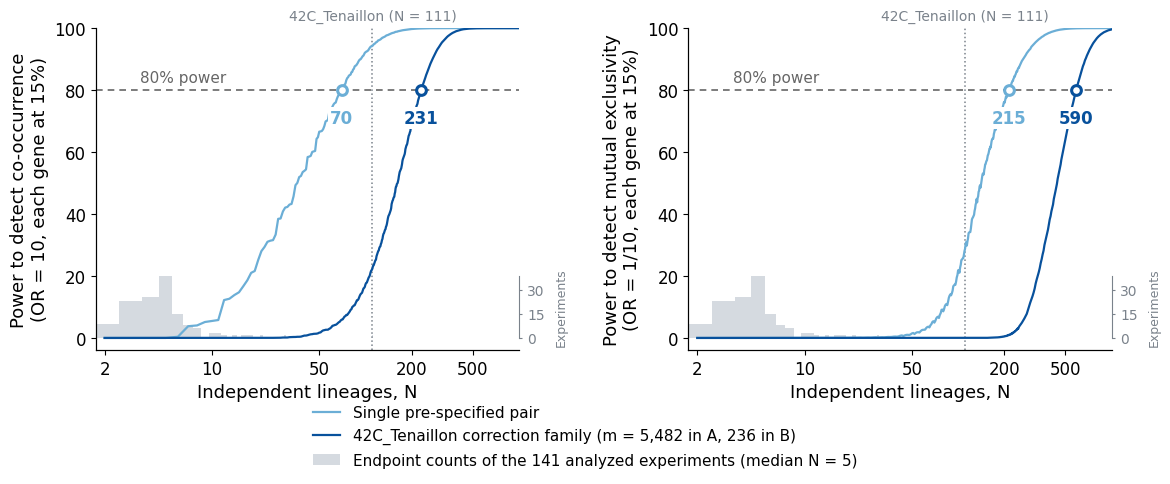

<Figure size 620x120 with 0 Axes>

In [3]:
# %% Parallel power panels: co-occurrence and mutual exclusivity, same structure
# Panels A and B carry NO legend and no size note of their own: the three entries are
# identical between them, so they share one legend, drawn under both and also exported
# on its own for assembly in Illustrator.
from matplotlib.patches import Patch

JCO = int(np.argmin(np.abs(OR_CO - 10.0)))
JMX = int(np.argmin(np.abs(OR_MX - 0.1)))
V3 = {
    "co": dict(single=SW["greater_single"][:, JCO], cons=SW["greater_cons"][:, JCO],
               m=M_CO, orr="OR = 10", what="co-occurrence"),
    "mx": dict(single=SW["less_single"][:, JMX], cons=SW["less_cons"][:, JMX],
               m=M_MX, orr="OR = 1/10", what="mutual exclusivity"),
}
for d in V3.values():
    d["n_single"], d["n_cons"] = n80(d["single"]), n80(d["cons"])
assert (V3["co"]["n_single"], V3["co"]["n_cons"]) == (N_SINGLE, N_CONS), "panel A disagrees with the sweep's OR = 10 curves"
for d in V3.values():
    print(f"{d['what']:20s} {d['orr']:10s} 80% power at N = {d['n_single']:>4}"
          f" (single pair) / {d['n_cons']:>4} (m = {d['m']:,})")

RUG_H = 0.20                       # share of panel height given to the size histogram

def draw_power_panel(ax, d):
    vals, cnts = np.unique(NOBS, return_counts=True)
    h = np.maximum(cnts / cnts.max() * (RUG_H * 100), 1.1)     # floor keeps the thin tail visible
    ax.bar(vals - 0.5, h, width=1.0, align="edge", color=HIST, edgecolor="none", zorder=1)

    ax.axhline(80, color=THRESH, ls=(0, (4, 3)), lw=1.2, zorder=3)
    ax.text(3.4, 81.5, "80% power", color=THRESH, fontsize=FS["annot"], va="bottom", ha="left")
    ax.axvline(N_TEN, color=MUTE, ls=":", lw=1.1, zorder=2)
    ax.text(N_TEN, 101.5, f"42C_Tenaillon (N = {N_TEN})", fontsize=FS["annot"] - 1,
            color=MUTE, ha="center", va="bottom", clip_on=False)

    ax.plot(NG, d["single"], color=BLUE_L, lw=1.6, zorder=5)
    ax.plot(NG, d["cons"], color=BLUE_D, lw=1.6, zorder=5)
    for nx, col in ((d["n_single"], BLUE_L), (d["n_cons"], BLUE_D)):
        ax.plot([nx], [80], marker="o", ms=7, mfc="white", mec=col, mew=2.2, zorder=6)
        ax.text(nx, 71, f"{nx}", color=col, fontsize=FS["annot"] + 1, ha="center",
                va="center", fontweight="bold", zorder=7,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.6))

    # The bars are a count, not a power. Give them their own scale on the right,
    # set so that the tallest bar sits at RUG_H of the panel height. Ticks are drawn
    # only over the band the bars occupy, so the scale cannot be read as the curves'.
    ylo, yhi = -4, 100
    ax.set_xscale("log"); ax.set_xlim(1.75, NG.max()); ax.set_ylim(ylo, yhi)   # axis ends where the curves end
    k = cnts.max() / (RUG_H * 100)                 # power units -> experiment counts
    ax2 = ax.twinx()
    ax2.set_ylim(ylo * k, yhi * k)
    # three ticks, 0, s and 2s, with s the largest of these round steps whose 2s still fits
    # under the tallest bar, so every tick sits over the band the bars occupy
    _s = max(s for s in (5, 10, 15, 20, 25, 30, 50, 100) if 2 * s <= cnts.max())
    ax2.set_yticks([0, _s, 2 * _s])
    ax2.spines["right"].set_visible(False)
    ax2.tick_params(axis="y", colors=MUTE, labelsize=FS["tick"] - 2, length=2.5)
    # a spine segment spanning only the counts, so the partial scale reads as deliberate
    ax2.plot([1.0, 1.0], [0, cnts.max()], transform=ax2.get_yaxis_transform(),
             color=MUTE, lw=0.8, clip_on=False, zorder=6)
    ax2.set_ylabel("Experiments", color=MUTE, fontsize=FS["axis"] - 4, rotation=90)
    ax2.yaxis.set_label_coords(1.085, 0.135)
    ax.set_xlabel("Independent lineages, N", fontsize=FS["axis"])
    ax.set_ylabel(f"Power to detect {d['what']}\n({d['orr']}, each gene at {F_MARG:.0%})",
                  fontsize=FS["axis"])
    ax.set_xticks([2, 10, 50, 200, 500])
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.tick_params(labelsize=FS["tick"]); ax.minorticks_off()

def power_legend():
    """The three entries shared by A and B, one per row. The correction family differs
    between the panels, so both sizes are named here rather than inside either panel."""
    return ([Line2D([0], [0], color=BLUE_L, lw=1.6),
             Line2D([0], [0], color=BLUE_D, lw=1.6),
             Patch(facecolor=HIST, edgecolor="none")],
            ["Single pre-specified pair",
             f"42C_Tenaillon correction family (m = {M_CO:,} in A, {M_MX} in B)",
             f"Endpoint counts of the {len(NOBS)} analyzed experiments"
             f" (median N = {int(np.median(NOBS))})"])

# ---- A and B as one figure, shared legend centered underneath ----------------------
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11.8, 5.1))
draw_power_panel(axA, V3["co"])
draw_power_panel(axB, V3["mx"])
plt.tight_layout()
fig.subplots_adjust(bottom=0.30, wspace=0.40)
_h, _l = power_legend()
fig.legend(_h, _l, loc="upper center", bbox_to_anchor=(0.5, 0.22), ncol=1, frameon=False,
           fontsize=FS["legend"], handlelength=1.8, labelspacing=0.55, handletextpad=0.8)
if SAVE:
    fig.savefig(FIG_DIR / "Figure_S2_AB.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_S2_AB.png", dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()

# ---- the same legend on its own, for Illustrator ----------------------------------
figL = plt.figure(figsize=(6.2, 1.2))
figL.legend(*power_legend(), loc="center", ncol=1, frameon=False, fontsize=FS["legend"],
            handlelength=1.8, labelspacing=0.55, handletextpad=0.8)
if SAVE:
    figL.savefig(FIG_DIR / "Figure_S2_key_AB.svg", bbox_inches="tight", facecolor="white")
    figL.savefig(FIG_DIR / "Figure_S2_key_AB.png", dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()

panel C surface: 349 sizes x 133 odds ratios, unsmoothed
   80% crossings: OR = 10 -> N = 70, OR = 0.1 -> N = 215
   circles mark those two points, and the N values are left off to be added by hand


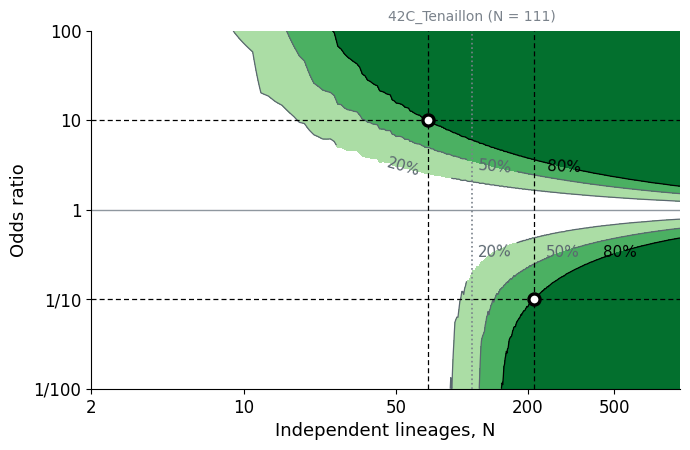

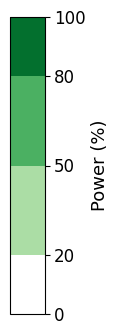

In [4]:
# %% Panel C: the detectability surface at the single-pair threshold
# Single-pair threshold only. The conservative family is left out on purpose: the two
# directions have different family sizes (5,482 and 236), so one surface cannot carry
# both. Panels A and B already show what multiplicity costs.
#
# NO SMOOTHING. Every integer N up to 250 and ~130 odds ratios, straight from the sweep,
# so the surface is resolved finely enough to contour directly and every quoted
# threshold is read off exact values.
#
# No title and no color bar inside the panel: the color bar is exported on its own below.
import matplotlib.colors as mcolors

ORS_C = np.concatenate([OR_MX, OR_CO[1:]])          # 1/100 .. 100, continuous through OR = 1
ZC = np.concatenate([SW["less_single"], SW["greater_single"][:, 1:]], axis=1).T   # (OR, N)

C_LEVELS = [0, 20, 50, 80, 100]                     # fill breaks = the contour levels
C_COLORS = ["#ffffff", plt.cm.Greens(0.34), plt.cm.Greens(0.60), plt.cm.Greens(0.86)]
C_CMAP = mcolors.ListedColormap(C_COLORS)
C_NORM = mcolors.BoundaryNorm(C_LEVELS, C_CMAP.N)

def n80_at(level, orr):
    """N from which power stays >= `level` along one odds-ratio row. Unsmoothed."""
    y = np.asarray(ZC[int(np.argmin(np.abs(ORS_C - orr))), :], float)
    ok = y >= level
    for i in range(len(NG)):
        if ok[i:].all():
            return int(NG[i])
    return None

C_MARKS = [(10.0, n80_at(80, 10.0)), (0.1, n80_at(80, 0.1))]
# Panel C must reproduce the light-curve crossings of Panels A and B exactly.
assert [n for _, n in C_MARKS] == [V3["co"]["n_single"], V3["mx"]["n_single"]], \
    "panel C disagrees with panels A and B"
print("panel C surface:", ZC.shape[1], "sizes x", ZC.shape[0], "odds ratios, unsmoothed")
print("   80% crossings: " + ", ".join(f"OR = {o:g} -> N = {n}" for o, n in C_MARKS))
print("   circles mark those two points, and the N values are left off to be added by hand")

def draw_panelC(ax, cax=None):
    cf = ax.contourf(NG, ORS_C, ZC, levels=C_LEVELS, colors=C_COLORS, zorder=1)
    thin = ax.contour(NG, ORS_C, ZC, levels=[20, 50], colors="#5b6770", linewidths=0.9, zorder=3)
    # 80% is picked out by color alone, at the same weight as the other two
    thick = ax.contour(NG, ORS_C, ZC, levels=[80], colors=INK, linewidths=0.9, zorder=4)
    def anchor(level, orr):
        return (n80_at(level, orr), orr)
    ax.clabel(thin, fmt=lambda v: f"{int(v)}%", fontsize=FS["annot"], inline_spacing=3,
              manual=[anchor(20, 3), anchor(50, 3), anchor(20, 1/3), anchor(50, 1/3)])
    ax.clabel(thick, fmt=lambda v: f"{int(v)}%", fontsize=FS["annot"], inline_spacing=3,
              manual=[anchor(80, 3), anchor(80, 1/3)])

    ax.axhline(1.0, color="#8f979f", lw=1.0, zorder=2)              # OR = 1, no association
    ax.axvline(N_TEN, color=MUTE, ls=":", lw=1.2, zorder=3)
    ax.text(N_TEN, 118, f"42C_Tenaillon (N = {N_TEN})", fontsize=FS["annot"] - 1,
            color=MUTE, ha="center", va="bottom", clip_on=False)

    # the two illustrative scenarios, marked but not labeled: a full crosshair on each,
    # so the odds ratio and the lineage number can both be read off the axes
    for orr, nx in C_MARKS:
        ax.axhline(orr, color=INK, ls=(0, (4, 2.5)), lw=0.9, zorder=3)
        ax.axvline(nx, color=INK, ls=(0, (4, 2.5)), lw=0.9, zorder=3)
        ax.plot([nx], [orr], marker="o", ms=8, mfc="white", mec=INK, mew=2.4, zorder=6)

    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(NG.min(), NG.max()); ax.set_ylim(0.01, 100)   # axis and lines end where the surface ends
    ax.set_xlabel("Independent lineages, N", fontsize=FS["axis"])
    ax.set_ylabel("Odds ratio", fontsize=FS["axis"])
    ax.set_xticks([2, 10, 50, 200, 500])
    ax.set_yticks([0.01, 0.1, 1, 10, 100])
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
    ax.get_yaxis().set_major_formatter(mpl.ticker.FuncFormatter(
        lambda v, _: (f"1/{round(1/v):g}" if v < 0.999 else f"{v:g}")))
    ax.tick_params(labelsize=FS["tick"]); ax.minorticks_off()
    if cax is not None:
        cb = ax.figure.colorbar(cf, cax=cax, ticks=C_LEVELS)
        cb.set_label("Power (%)", fontsize=FS["axis"]); cb.ax.tick_params(labelsize=FS["tick"])
    return cf

fig, ax = plt.subplots(figsize=(7.0, 4.6))
draw_panelC(ax)
plt.tight_layout()
if SAVE:
    fig.savefig(FIG_DIR / "Figure_S2_C.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_S2_C.png", dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()

# ---- the color bar on its own, for Illustrator -----------------------------------
figC = plt.figure(figsize=(1.15, 3.3))
cax = figC.add_axes([0.06, 0.05, 0.30, 0.90])
cb = mpl.colorbar.ColorbarBase(cax, cmap=C_CMAP, norm=C_NORM, boundaries=C_LEVELS,
                               ticks=C_LEVELS, spacing="proportional")
cb.set_label("Power (%)", fontsize=FS["axis"])
cb.ax.tick_params(labelsize=FS["tick"]); cb.outline.set_linewidth(0.8)
if SAVE:
    figC.savefig(FIG_DIR / "Figure_S2_key_C.svg", bbox_inches="tight", facecolor="white")
    figC.savefig(FIG_DIR / "Figure_S2_key_C.png", dpi=DPI, bbox_inches="tight", facecolor="white")
plt.show()


key of A and B: 0.75 in tall, in a 0.93 in gap between the A/B row and C


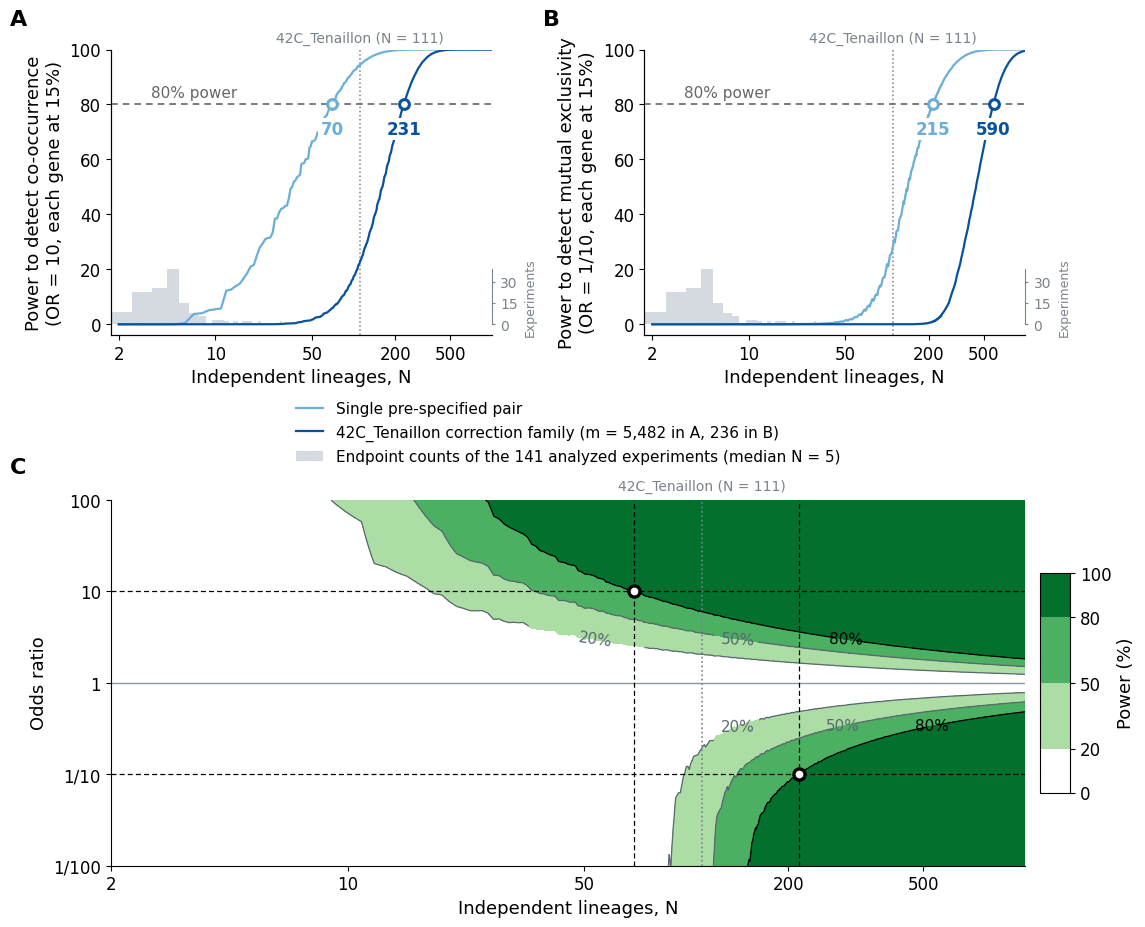

In [5]:
# %% The three panels together, with the key of A and B, the color bar of C and the panel
# letters. No title: the title goes in the caption.
fig = plt.figure(figsize=(11.8, 10.6))
gs = fig.add_gridspec(3, 2, height_ratios=[1.0, 0.10, 1.28], hspace=0.30, wspace=0.40)
axA = fig.add_subplot(gs[0, 0])
axB = fig.add_subplot(gs[0, 1])
axC = fig.add_subplot(gs[2, 0:2])          # spans both columns (the band gs[1, :] takes the key of A and B)
draw_power_panel(axA, V3["co"])
draw_power_panel(axB, V3["mx"])
draw_panelC(axC)                           # cax omitted: the color bar is placed below

# Color bar of C: right of the panel and centered on it, drawn like the standalone key of C.
CBAR_GAP, CBAR_W, CBAR_FRAC = 0.15, 0.30, 0.60   # inches from the panel, inches wide, share of C's height
_W, _H = fig.get_figwidth(), fig.get_figheight()
_pc = axC.get_position()
cax = fig.add_axes([_pc.x1 + CBAR_GAP / _W, _pc.y0 + _pc.height * (1 - CBAR_FRAC) / 2,
                    CBAR_W / _W, _pc.height * CBAR_FRAC])
cb = mpl.colorbar.ColorbarBase(cax, cmap=C_CMAP, norm=C_NORM, boundaries=C_LEVELS,
                               ticks=C_LEVELS, spacing="proportional")
cb.set_label("Power (%)", fontsize=FS["axis"])
cb.ax.tick_params(labelsize=FS["tick"]); cb.outline.set_linewidth(0.8)

# Key of A and B: centered under the A/B row, halfway between that row's ink (tick labels and
# axis titles) and the ink of C (its 42C_Tenaillon label). The run stops if it does not fit.
fig.canvas.draw()
_r = fig.canvas.get_renderer()
_ab_low = min(a.get_tightbbox(_r).y0 for a in (axA, axB))      # display pixels
_c_top = axC.get_tightbbox(_r).y1
_x_mid = (axA.get_position().x0 + axB.get_position().x1) / 2
leg = fig.legend(*power_legend(), loc="center",
                 bbox_to_anchor=(_x_mid, (_ab_low + _c_top) / 2 / fig.bbox.height),
                 ncol=1, frameon=False, fontsize=FS["legend"], handlelength=1.8,
                 labelspacing=0.55, handletextpad=0.8)
fig.canvas.draw()
_lb = leg.get_window_extent(_r)
if not (_c_top < _lb.y0 and _lb.y1 < _ab_low):
    raise RuntimeError("the key of A and B does not fit between the A/B row and panel C")

# Panel letters: each sits PANEL_LETTER_PAD above the top of its panel's ink and
# PANEL_LETTER_LEFT left of the ink's left edge (axis titles included). A and C share the left
# column's edge, so they line up.
PANEL_LETTER_PAD = 0.06      # inches between the top of a panel's ink and its letter's baseline
PANEL_LETTER_LEFT = 0.15     # inches between a letter and the left edge of its panel's ink
_x_left = min(a.get_tightbbox(_r).x0 for a in (axA, axC)) / fig.bbox.width - PANEL_LETTER_LEFT / _W
_row1 = max(a.get_tightbbox(_r).y1 for a in (axA, axB)) / fig.bbox.height + PANEL_LETTER_PAD / _H
_row2 = _c_top / fig.bbox.height + PANEL_LETTER_PAD / _H
for _letter, _x, _y in [("A", _x_left, _row1),
                        ("B", axB.get_tightbbox(_r).x0 / fig.bbox.width - PANEL_LETTER_LEFT / _W, _row1),
                        ("C", _x_left, _row2)]:
    fig.text(_x, _y, _letter, ha="left", va="baseline", fontsize=FS["panel_label"],
             fontweight="bold", color=INK)

if SAVE:
    fig.savefig(FIG_DIR / "Figure_S2.svg", bbox_inches="tight", facecolor="white")
    fig.savefig(FIG_DIR / "Figure_S2.png", dpi=DPI, bbox_inches="tight", facecolor="white")
print(f"key of A and B: {(_lb.y1 - _lb.y0) / fig.dpi:.2f} in tall, in a "
      f"{(_ab_low - _c_top) / fig.dpi:.2f} in gap between the A/B row and C")
plt.show()

In [6]:
# %% Rewrite SVG fonts to Arial so the text opens in Arial in Illustrator and stays editable
import re
for f in sorted(FIG_DIR.glob("*.svg")):
    t = f.read_text()
    t = re.sub(r'(font:\s*(?:[a-z]+\s+|\d+\s+)*[\d.]+px\s+)[^;"]*', r'\1Arial, Helvetica, sans-serif', t)
    f.write_text(t)
print("SVG fonts rewritten to Arial")


SVG fonts rewritten to Arial
